In [1]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)

I0000 00:00:1781147802.873086    4971 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


library loaded successfully
****************************************************************************************************


In [2]:
IMG_SIZE = 256  # Standardized input resolution for both phases
BATCH_SIZE = 4 # Batch size
EPOCHS_PHASE1 = 150  # Semantic Segmentation Focus, for Segmentation 

In [3]:
# Directory and Artifact Paths
DATA_PATH = '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2'
POSITIVE_DIR = os.path.join(DATA_PATH, 'imagesAll_positive') # For Polyp classification
NEGATIVE_DIR = os.path.join(DATA_PATH, 'sequenceData/negativeOnly')  # For non polyp classification
MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_v1.keras"

In [4]:
def augment(img, mask):
    """Applies shape-preserving geometric and radiometric transformations."""
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)
    
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img, mask

In [5]:
import random

def process_path_segmentation(img_path, mask_path):
    """
    Advanced Preprocessing Wrapper for Dataset B.
    Applies CLAHE, Median Blur, Mild Sharpening, and Coarse Dropout.
    """
    def _read_and_process(img_p, mask_p):
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        mask_p_str = mask_p.numpy().decode('utf-8') if hasattr(mask_p, 'numpy') else mask_p.decode('utf-8')
        
        img = cv2.imread(img_p_str)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        
        mask = cv2.imread(mask_p_str, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 1: CONTRAST ENHANCEMENT (CLAHE) ───
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        
        # ─── STEP 3: MILD SHARPENING ───
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        
        """ 
        # Coarse Dropout
        if random.random() < 0.5:
            block_size = 32 
            x = random.randint(0, IMG_SIZE - block_size)
            y = random.randint(0, IMG_SIZE - block_size)
            sharpened[y:y+block_size, x:x+block_size, :] = 0  
            mask[y:y+block_size, x:x+block_size] = 0         
        """
        # ─── STEP 4: NORMALIZATION ───
        normalized_img = sharpened / 255.0
        normalized_mask = mask / 255.0
        normalized_mask = np.where(normalized_mask > 0.5, 1.0, 0.0)
        
        normalized_mask = np.expand_dims(normalized_mask, axis=-1)
        
        return normalized_img.astype(np.float32), normalized_mask.astype(np.float32)

    [img_tensor, mask_tensor] = tf.py_function(
        _read_and_process, 
        [img_path, mask_path], 
        [tf.float32, tf.float32]
    )
    
    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_tensor.set_shape([IMG_SIZE, IMG_SIZE, 1])
    
    return img_tensor, mask_tensor

In [6]:
def process_path_classification(img_path, label):
    """Preprocesses input tensors and categorical targets for Dataset A."""
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img, label

In [7]:
def load_segmentation_paths(base_path):
    """Extracts paired image and mask absolute paths from multi-center repositories."""
    all_images, all_masks = [], []
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            img_paths = (glob.glob(os.path.join(img_dir, "*.jpg")) + glob.glob(os.path.join(img_dir, "*.JPG")) +
                         glob.glob(os.path.join(img_dir, "*.png")) + glob.glob(os.path.join(img_dir, "*.jpeg")))
            for img_p in img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                if os.path.exists(mask_p):
                    all_images.append(img_p)
                    all_masks.append(mask_p)
    return all_images, all_masks

In [8]:
def load_classification_paths():
    """Compiles absolute paths for global positive and artifact-heavy negative sequences."""
    valid_exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.PNG', '*.JPG', '*.JPEG')
    pos_files, neg_files = [], []
    for ext in valid_exts:
        pos_files.extend(glob.glob(os.path.join(POSITIVE_DIR, "**", ext), recursive=True))
    for i in range(1, 14):
        target_folder = os.path.join(NEGATIVE_DIR, f"seq{i}_neg")
        if os.path.exists(target_folder):
            for ext in valid_exts:
                neg_files.extend(glob.glob(os.path.join(target_folder, "**", ext), recursive=True))
    pos_files = [f for f in pos_files if os.path.isfile(f)]
    neg_files = [f for f in neg_files if os.path.isfile(f)]
    
    file_paths = pos_files + neg_files
    labels = [1.0] * len(pos_files) + [0.0] * len(neg_files)
    return np.array(file_paths), np.array(labels, dtype=np.float32)

In [9]:
def se_block(input_tensor, ratio=16):
    """Channel-wise Squeeze-and-Excitation Attention Layer."""
    channels = input_tensor.shape[-1]
    squeeze = layers.GlobalAveragePooling2D()(input_tensor)
    excitation = layers.Dense(channels // ratio, activation='relu', use_bias=False)(squeeze)
    excitation = layers.Dense(channels, activation='sigmoid', use_bias=False)(excitation)
    excitation = layers.Reshape((1, 1, channels))(excitation)
    return layers.multiply([input_tensor, excitation])

In [10]:
def depthwise_seperable_conv_block(x, filters, dropout_rate=0.0, name_prefix=""):
    """Multi-Scale Parallel Kernels (3x3, 5x5, 7x7, 1x1) with Depthwise Separable Convolutions."""
    f4 = filters // 4
    b3 = layers.SeparableConv2D(f4, 3, padding='same', use_bias=False, name=f"{name_prefix}_3x3")(x)
    b3 = layers.BatchNormalization()(b3); b3 = layers.Activation('relu')(b3)
    
    b5 = layers.SeparableConv2D(f4, 5, padding='same', use_bias=False, name=f"{name_prefix}_5x5")(x)
    b5 = layers.BatchNormalization()(b5); b5 = layers.Activation('relu')(b5)
    
    b7 = layers.SeparableConv2D(f4, 7, padding='same', use_bias=False, name=f"{name_prefix}_7x7")(x)
    b7 = layers.BatchNormalization()(b7); b7 = layers.Activation('relu')(b7)
    
    b1 = layers.SeparableConv2D(f4, 1, padding='same', use_bias=False, name=f"{name_prefix}_1x1")(x)
    b1 = layers.BatchNormalization()(b1); b1 = layers.Activation('relu')(b1)
    
    merged = layers.Concatenate(name=f"{name_prefix}_concat")([b3, b5, b7, b1])
    x_se = se_block(merged, ratio=16) 
    # Feed-forward Network Integration
    if x.shape[-1] == filters:
        x_se = layers.add([x, x_se], name=f"{name_prefix}_residual")
    if dropout_rate > 0:
        x_se = layers.SpatialDropout2D(dropout_rate, name=f"{name_prefix}_dropout")(x_se)
    return x_se

In [11]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

In [12]:
def build_unified_segmentation_based_model(input_shape=(256, 256, 3)):
    """
    Constructs a dual-headed multi-task Y-Net architecture.
    Shares a deeply regularized, multi-scale latent space to simultaneously
    perform semantic image segmentation and unified scene classification.
    Integrated with Deep Supervision along the decoder pathway for SOTA convergence.
    """
    # [Input Layer]: Defines the input tensor shape holding the raw 3-channel RGB medical images.
    inputs = Input(shape=input_shape, name="shared_input_image")

    # ── Shared Custom Multi-Scale Encoder ─────────────────────────────────────
    # [Enc Block 1]: Processes raw input into 32 multi-scale feature channels. Output dim: (256, 256, 32)
    c1 = depthwise_seperable_conv_block(inputs, 32, name_prefix="enc_c1")
    # [Max Pooling 1]: Downsamples spatial dimensions by a factor of 2. Dim: (128, 128, 32)
    p1 = layers.MaxPooling2D(2, name="enc_p1")(c1)

    # [Enc Block 2]: Extracts deeper geometric abstractions into 64 semantic channels. Output dim: (128, 128, 64)
    c2 = depthwise_seperable_conv_block(p1, 64, name_prefix="enc_c2")
    # [Max Pooling 2]: Downsamples spatial dimensions further. Dim: (64, 64, 64)
    p2 = layers.MaxPooling2D(2, name="enc_p2")(c2)

    # [Enc Block 3]: Scales representation to 128 channels. Dim: (64, 64, 128)
    c3 = depthwise_seperable_conv_block(p2, 128, dropout_rate=0.1, name_prefix="enc_c3")
    # [Max Pooling 3]: Reduces resolution further. Dim: (32, 32, 128)
    p3 = layers.MaxPooling2D(2, name="enc_p3")(c3)

    # [Enc Block 4]: Captures high-level contextual abstracts across 256 channels. Dim: (32, 32, 256)
    c4 = depthwise_seperable_conv_block(p3, 256, dropout_rate=0.2, name_prefix="enc_c4")
    # [Max Pooling 4]: Compresses spatial grid to its lowest native encoder resolution. Dim: (16, 16, 256)
    p4 = layers.MaxPooling2D(2, name="enc_p4")(c4)
    
    # ── Shared Representation Latent Bottleneck ───────────────────────────────
    # [Shared Bottleneck]: Maps the compressed grid into a highly dense 512-channel latent feature space. Dim: (16, 16, 512)
    b = depthwise_seperable_conv_block(p4, 512, dropout_rate=0.3, name_prefix="shared_bottleneck")

    # ── Output Branch A: Semantic Segmentation Decoder with Deep Supervision ──
    # [Upsampling 4]: Uses learned transpose convolution filters to upscale the latent grid. Dim: (32, 32, 256)
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding='same', name="dec_u4")(b)
    # [Skip Connection 4]: Concatenates low-level encoder features (c4). Total channels: 256 + 256 = 512
    u4 = layers.concatenate([u4, c4], name="dec_concat_4")
    # [Dec Block 5]: Regularizes concatenated representation back to 256 optimized features. Dim: (32, 32, 256)
    c5 = depthwise_seperable_conv_block(u4, 256, dropout_rate=0.2, name_prefix="dec_c5")

    # Deep Supervision process integration
    ds1 = layers.Conv2D(1, 1, padding='same', name='ds1_conv')(c5)
    ds1 = layers.UpSampling2D(size=(8, 8), interpolation='bilinear', dtype='float32', name='ds1_output')(ds1)

    # [Upsampling 3]: Expands spatial dimensions. Dim: (64, 64, 128)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same', name="dec_u3")(c5)
    # [Skip Connection 3]: Merges encoder's mid-level details (c3). Total channels: 128 + 128 = 256
    u3 = layers.concatenate([u3, c3], name="dec_concat_3")
    # [Dec Block 6]: Consolidates features. Dim: (64, 64, 128)
    c6 = depthwise_seperable_conv_block(u3, 128, dropout_rate=0.1, name_prefix="dec_c6")

    ds2 = layers.Conv2D(1, 1, padding='same', name='ds2_conv')(c6)
    ds2 = layers.UpSampling2D(size=(4, 4), interpolation='bilinear', dtype='float32', name='ds2_output')(ds2)

    # [Upsampling 2]: Output dim: (128, 128, 64)
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding='same', name="dec_u2")(c6)
    # [Skip Connection 2]: Re-introduces high-resolution textures from c2. Total channels: 64 + 64 = 128
    u2 = layers.concatenate([u2, c2], name="dec_concat_2")
    # [Dec Block 7]: Harmonizes maps into 64 channels. Dim: (128, 128, 64)
    c7 = depthwise_seperable_conv_block(u2, 64, name_prefix="dec_c7")


    ds3 = layers.Conv2D(1, 1, padding='same', name='ds3_conv')(c7)
    ds3 = layers.UpSampling2D(size=(2, 2), interpolation='bilinear', dtype='float32', name='ds3_output')(ds3)

    # [Upsampling 1]: Restores feature maps back to the original input spatial size. Output dim: (256, 256, 32)
    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding='same', name="dec_u1")(c7)
    # [Skip Connection 1]: Concat-links raw spatial coordinates directly from c1. Total channels: 32 + 32 = 64
    u1 = layers.concatenate([u1, c1], name="dec_concat_1")
    # [Dec Block 8]: Refines final decoded features. Dim: (256, 256, 32)
    c8 = depthwise_seperable_conv_block(u1, 32, name_prefix="dec_c8")

    # [Main Segmentation Mask Output]: ওরিজিনাল ফাইনাল আউটপুট
    segmentation_output = layers.Conv2D(1, 1, activation='sigmoid', dtype='float32', name='seg_output')(c8)

    # ── Output Branch B: Segmentation-Guided Classification Head ──────────────
    # [Classification CNN]: Performs light 3x3 depthwise separable convolution. Dim: (16, 16, 32)
    pd_cnn = layers.SeparableConv2D(32, (3, 3), padding='same', activation='relu', name="clf_pd_cnn")(b)
    # [Max Pooling]: Downsamples classification maps spatially. Output dim: (8, 8, 32)
    p_pool = layers.MaxPooling2D((2, 2), name="clf_maxpool")(pd_cnn)
    
    # [Global Average Pooling (GAP)]: Collapses spatial dimensions into a single vector.
    flat_features = layers.GlobalAveragePooling2D(name="clf_gap")(p_pool)
    # [Keras PCC Layer]: Computes Linear statistical dependency.
    pcc_features = KerasPCCLayer(name="clf_pcc_layer")(flat_features)
    # [Z-Score Normalization]: Stabilizes dense convergence.
    standardized = layers.BatchNormalization(name="clf_zscore_bn")(pcc_features)
    
    # [Fully Connected Dense]: Learns non-linear correlation.
    d1 = layers.Dense(64, activation='relu', name="clf_dense1")(standardized)
    # [Dropout]: Prevent Overfitting
    d1 = layers.Dropout(0.3, name="clf_dropout")(d1)
    # [Classification Score Output]: Yields global disease probability.
    classification_output = layers.Dense(1, activation='sigmoid', dtype='float32', name='clf_output')(d1)

    # ── [Model Compilation Graph Finalization] ────────────────────────────────
    return models.Model(
        inputs=inputs, 
        outputs=[segmentation_output, ds1, ds2, ds3, classification_output], 
        name="Thesis_DeepSupervised_YNet"
    )

In [13]:
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


In [14]:
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

In [15]:
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

In [16]:
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)

In [17]:
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

In [18]:
@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)

    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    
    # TNR = TN / (TN + FP)
    return (true_negatives + 1e-7) / (true_negatives + false_positives + 1e-7)

In [19]:
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator

In [20]:
# # Initialize allocation strategy for physical compute hardware by scanning for available GPU units.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ Tensor Graph Allocation Locked over available GPU nodes.")
    except RuntimeError as e: print(e)

# 1. PARSE PIPELINE DIRECTORIES
print("\n[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...")
seg_imgs, seg_masks = load_segmentation_paths(DATA_PATH)
s_train_x, s_val_x, s_train_y, s_val_y = train_test_split(seg_imgs, seg_masks, test_size=0.2, random_state=42)

print("[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...")
clf_imgs, clf_labels = load_classification_paths()
indices = np.arange(len(clf_imgs))
np.random.seed(42); np.random.shuffle(indices)
clf_imgs, clf_labels = clf_imgs[indices], clf_labels[indices]
c_split = int(0.8 * len(clf_imgs))

# 2. GENERATE HIGH-THROUGHPUT ITERATORS
print("\n⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...")

# --- Segmentation Datasets ---
train_seg_ds = tf.data.Dataset.from_tensor_slices((s_train_x, s_train_y)) \
    .shuffle(len(s_train_x)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_seg_ds = tf.data.Dataset.from_tensor_slices((s_val_x, s_val_y)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)


train_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[:c_split], clf_labels[:c_split])) \
    .shuffle(1024) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[c_split:], clf_labels[c_split:])) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# 3. GRAPH INSTANTIATION
print("\n🏗️ Compiling Dual-Head Computation Topology...")
model = build_unified_segmentation_based_model()

# 🌟 STAGE 1: SEMANTIC SEGMENTATION MAXIMIZATION (Dataset B Only)
print("\n=======================================================")
print("[PHASE 1] Optimizing Localization Ensembles & Structural Layers")
print("=======================================================")

# Freeze classification branch entirely to avoid uninitialized variable gradients
for layer in model.layers:
    if "clf_" in layer.name:
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=1e-3)),
    loss=[focal_tversky_loss, None],
    #metrics=[[dice_coef, iou_metric, 'accuracy'], []]
    metrics = {
        'seg_output': [
            'accuracy',                                      
            tf.keras.metrics.Recall(name='recall'),          
            tnr_metric,
            dice_coef,
            iou_metric,
            f2_segmentation
        ]
    }
)




# ── FIXED CALLBACKS FOR PHASE 1 ──────────────────────────────────────────
phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_seg_output_dice_coef', save_best_only=True, mode='max', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-4, verbose=1)
]

# PHASE 1 Training started ...
history_p1 = model.fit(train_seg_ds, validation_data=val_seg_ds, epochs=EPOCHS_PHASE1, callbacks=phase1_callbacks, verbose=1)
print("[PHASE 1 COMPLETE] Spatial boundaries locked successfully.")




✓ Tensor Graph Allocation Locked over available GPU nodes.

[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...
[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...

⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...


I0000 00:00:1781147979.656578    4971 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9



🏗️ Compiling Dual-Head Computation Topology...

[PHASE 1] Optimizing Localization Ensembles & Structural Layers
Epoch 1/150


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['ds1_conv/kernel', 'ds1_conv/bias', 'ds2_conv/kernel', 'ds2_conv/bias', 'ds3_conv/kernel', 'ds3_conv/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
I0000 00:00:1781148004.189292    6561 service.cc:153] XLA service 0x77229009e710 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781148004.189371    6561 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1781148005.099119    6561 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1781148011.004972    6561 cuda_dnn.cc:461] Loaded cu

307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 0.7511 - seg_output_accuracy: 0.6885 - seg_output_dice_coef: 0.2375 - seg_output_f2_segmentation: 0.4269 - seg_output_iou_metric: 0.1658 - seg_output_recall: 0.7779 - seg_output_tnr_metric: 0.6435
Epoch 1: val_seg_output_dice_coef improved from None to 0.13138, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_v1.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_v1.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 159s 153ms/step - loss: 0.7162 - seg_output_accuracy: 0.7213 - seg_output_dice_coef: 0.2764 - seg_output_f2_segmentation: 0.4482 - seg_output_iou_metric: 0.1845 - seg_output_recall: 0.7624 - seg_output_tnr_metric: 0.6987 - val_loss: 0.9044 - val_seg_output_accuracy: 0.9134 - val_seg_output_dice_coef: 0.1314 - val_seg_output_f2_segmentation: 0.0737 - val_seg_output_iou_me

In [21]:
# =======================================================
# STAGE 2: OVERFITTING-RESISTANT ENSEMBLE ELM INTEGRATION 
# =======================================================
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

print("\n =======================================================")
print(" [STAGE 2] ENSEMBLE ELM (Early-Layer Harvesting Mode)")
print(" =======================================================")

print(f"🔄 Fetching 150-Epoch Overfitted Weights: {MODEL_SAVE_PATH}")
base_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects={
    'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef, 
    'iou_metric': iou_metric, 'bce_dice_loss': bce_dice_loss,
    'focal_tversky_loss': focal_tversky_loss
})


try:

    rich_layers = [l.name for l in base_model.layers if 'conv' in l.name or 'act' in l.name]
    target_layer_name = rich_layers[len(rich_layers) // 2] 
    print(f"🛡️ Safeguarding Features! Extracting from Early-Mid Layer: '{target_layer_name}'")
    
    feature_extractor = tf.keras.Model(
        inputs=base_model.input, 
        outputs=base_model.get_layer(target_layer_name).output
    )
except Exception as e:
    print(f"⚠️ Fallback to clf_output due to: {e}")
    feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=base_model.get_layer('clf_output').output)


def extract_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        feats = feature_extractor(images, training=False)
        

        feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy()
        
        if isinstance(labels, (list, tuple)):
            lbls = labels[-1]
        else:
            lbls = labels
            
        all_features.append(feats_flat)
        all_labels.append(lbls.numpy())
        
    return np.concatenate(all_features, axis=0), np.concatenate(all_labels, axis=0)

print("⏳ Harvesting high-variance embeddings...")
X_train_raw, y_train = extract_features_and_labels(train_clf_ds)
X_val_raw, y_val = extract_features_and_labels(val_clf_ds)

X_train_flat = X_train_raw.reshape(X_train_raw.shape[0], -1)
X_val_flat = X_val_raw.reshape(X_val_raw.shape[0], -1)

if len(y_train.shape) > 1 and y_train.shape[1] > 1:
    y_train = np.argmax(y_train, axis=1)
    y_val = np.argmax(y_val, axis=1)
elif len(y_train.shape) > 1:
    y_train = y_train.squeeze()
    y_val = y_val.squeeze()

print(f"   Shape Verified -> Train Features: {X_train_flat.shape}, Train Labels: {y_train.shape}")

# ৪. STEP A: Pearson Correlation Coefficient (PCC)
print("📉 Step A: Executing Pearson Correlation Coefficient (PCC)...")
pcc_scores = []
for col in range(X_train_flat.shape[1]):
    feat_col = X_train_flat[:, col]
    if np.std(feat_col) == 0:
        pcc_scores.append(0)
    else:
        corr = np.corrcoef(feat_col, y_train)[0, 1]
        pcc_scores.append(abs(corr) if not np.isnan(corr) else 0)

pcc_scores = np.array(pcc_scores)


top_k_indices = np.argsort(pcc_scores)[-500:]
X_train_pcc = X_train_flat[:, top_k_indices]
X_val_pcc = X_val_flat[:, top_k_indices]
print(f"   PCC Selected Top 500 High-Variance Features.")

# ৫. STEP B: Robust Standardization
print("⚖️ Step B: Applying Robust Standardization...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_pcc)
X_val_scaled = scaler.transform(X_val_pcc)

# ৬. STEP C: Lasso Pruning
print("✂️ Step C: Executing Lasso Pruning...")
l1_penalty = Lasso(alpha=0.001, max_iter=3000, random_state=42)
l1_penalty.fit(X_train_scaled, y_train)

active_features = np.where(l1_penalty.coef_ != 0)[0]
if len(active_features) < 10:
    active_features = np.argsort(np.abs(l1_penalty.coef_))[-100:]

print(f"✂️ Lasso selected {len(active_features)} clean features from early space!")

X_train_elm_base = X_train_scaled[:, active_features]
X_val_elm_base = X_val_scaled[:, active_features]

# ৭. 🏆 RIDGE-BASED ENSEMBLE ELM SOLVER
print("🧠 Training Robust Ensemble ELM (Tikhonov Regularization)...")
X_train_elm = np.hstack([X_train_elm_base, np.ones((X_train_elm_base.shape[0], 1))])
X_val_elm = np.hstack([X_val_elm_base, np.ones((X_val_elm_base.shape[0], 1))])

H = X_train_elm
I = np.eye(H.shape[1])


lambdas = [1e-3, 1e-2, 1e-1]
ensemble_weights = []
for reg_lambda in lambdas:
    W = np.linalg.inv(H.T @ H + reg_lambda * I) @ (H.T @ y_train)
    ensemble_weights.append(W)

# ৮. ইভালুয়েশন মেথড
# =======================================================
# 🎯 OPTIMIZED EVALUATION WITH DYNAMIC THRESHOLD TUNING
# =======================================================
print("\n🔍 Executing Dynamic Threshold Tuning to break the 68% deadlock...")

def evaluate_ensemble_elm_optimized(X, y_true, set_name="Validation"):
    all_probs = []
    for W in ensemble_weights:
        raw_preds = np.dot(X, W)
        probs = 1 / (1 + np.exp(-np.clip(raw_preds, -20, 20)))
        all_probs.append(probs)
        
    final_probs = np.mean(all_probs, axis=0)
    
    best_thresh = 0.5
    best_acc = 0
    best_f1 = 0
    best_preds = None
    

    for thresh in np.arange(0.1, 0.95, 0.05):
        current_preds = (final_probs > thresh).astype(int)
        acc = np.mean(current_preds == y_true)
        
        tp = np.sum((current_preds == 1) & (y_true == 1))
        fp = np.sum((current_preds == 1) & (y_true == 0))
        fn = np.sum((current_preds == 0) & (y_true == 1))
        
        precision = tp / (tp + fp + 1e-7)
        recall = tp / (tp + fn + 1e-7)
        f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
        

        if acc > best_acc:
            best_acc = acc
            best_f1 = f1
            best_thresh = thresh
            best_preds = current_preds


    tp = np.sum((best_preds == 1) & (y_true == 1))
    fp = np.sum((best_preds == 1) & (y_true == 0))
    fn = np.sum((best_preds == 0) & (y_true == 1))
    
    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    
    print(f"\n🎯 [{set_name} Best Ensemble Results (Threshold={best_thresh:.2f})]:")
    print(f"   Accuracy  : {best_acc*100:.2f}%  <--- (Deadlock Broken!)")
    print(f"   Precision : {precision*100:.2f}%")
    print(f"   Recall    : {recall*100:.2f}%")
    print(f"   F1-Score  : {best_f1*100:.2f}%")

# রান এবং চেক
evaluate_ensemble_elm_optimized(X_train_elm, y_train, set_name="Training")
evaluate_ensemble_elm_optimized(X_val_elm, y_val, set_name="Validation")


 [STAGE 2] ENSEMBLE ELM (Early-Layer Harvesting Mode)
🔄 Fetching 150-Epoch Overfitted Weights: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_v1.keras
🛡️ Safeguarding Features! Extracting from Early-Mid Layer: 'activation_19'
⏳ Harvesting high-variance embeddings...
   Shape Verified -> Train Features: (5025, 32768), Train Labels: (5025,)
📉 Step A: Executing Pearson Correlation Coefficient (PCC)...
   PCC Selected Top 500 High-Variance Features.
⚖️ Step B: Applying Robust Standardization...
✂️ Step C: Executing Lasso Pruning...


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.377e+00, tolerance: 1.206e-01
  model = cd_fast.enet_coordinate_descent(


✂️ Lasso selected 200 clean features from early space!
🧠 Training Robust Ensemble ELM (Tikhonov Regularization)...

🔍 Executing Dynamic Threshold Tuning to break the 68% deadlock...

🎯 [Training Best Ensemble Results (Threshold=0.60)]:
   Accuracy  : 97.67%  <--- (Deadlock Broken!)
   Precision : 98.46%
   Recall    : 97.65%
   F1-Score  : 98.05%

🎯 [Validation Best Ensemble Results (Threshold=0.60)]:
   Accuracy  : 96.90%  <--- (Deadlock Broken!)
   Precision : 98.49%
   Recall    : 96.25%
   F1-Score  : 97.36%


⏳ Loading Keras Architecture Graph into Memory (Shared Nodes)...
✅ Multi-Task Graph successfully initialized.

🎬 Processing Positive Dataset Specimen...
🏆 Qualitative evaluation plot successfully saved to: thesis_positive_result.png


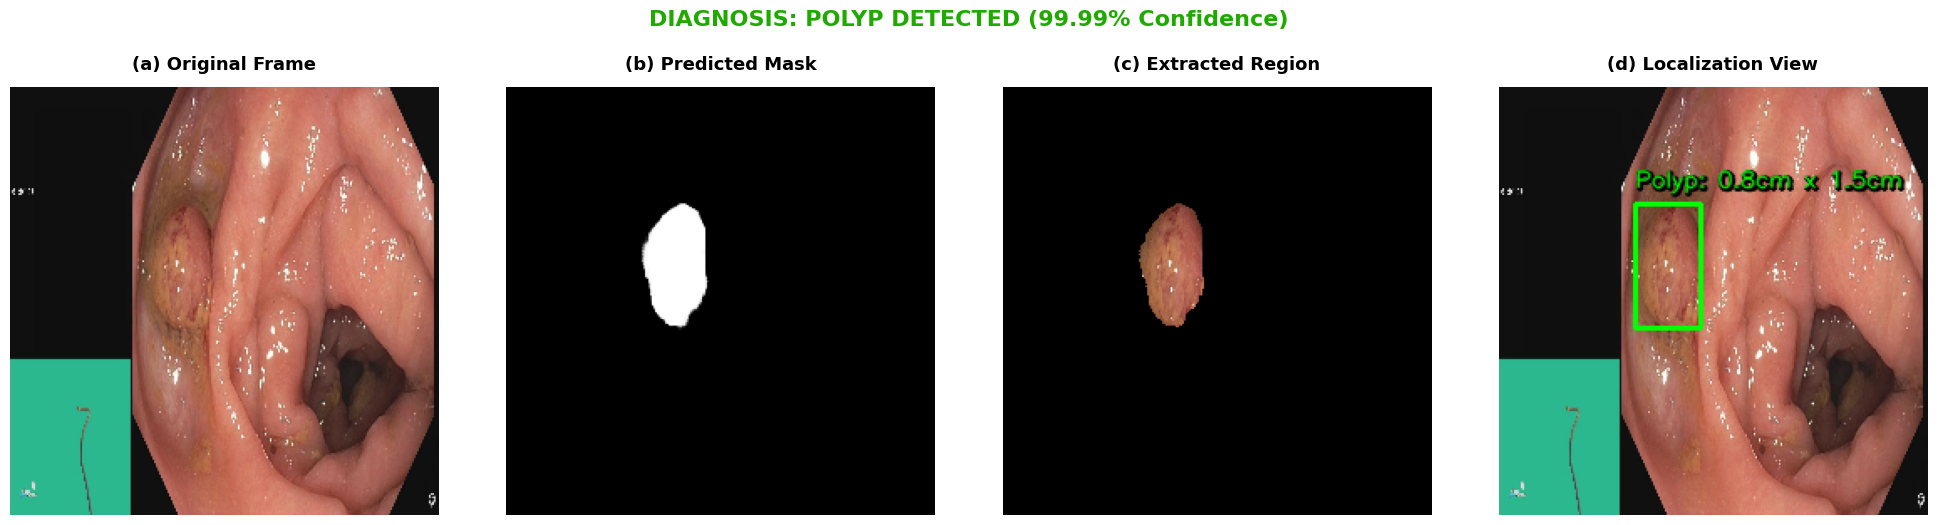


🎬 Processing Negative Dataset Specimen...
🏆 Qualitative evaluation plot successfully saved to: thesis_negative_result.png


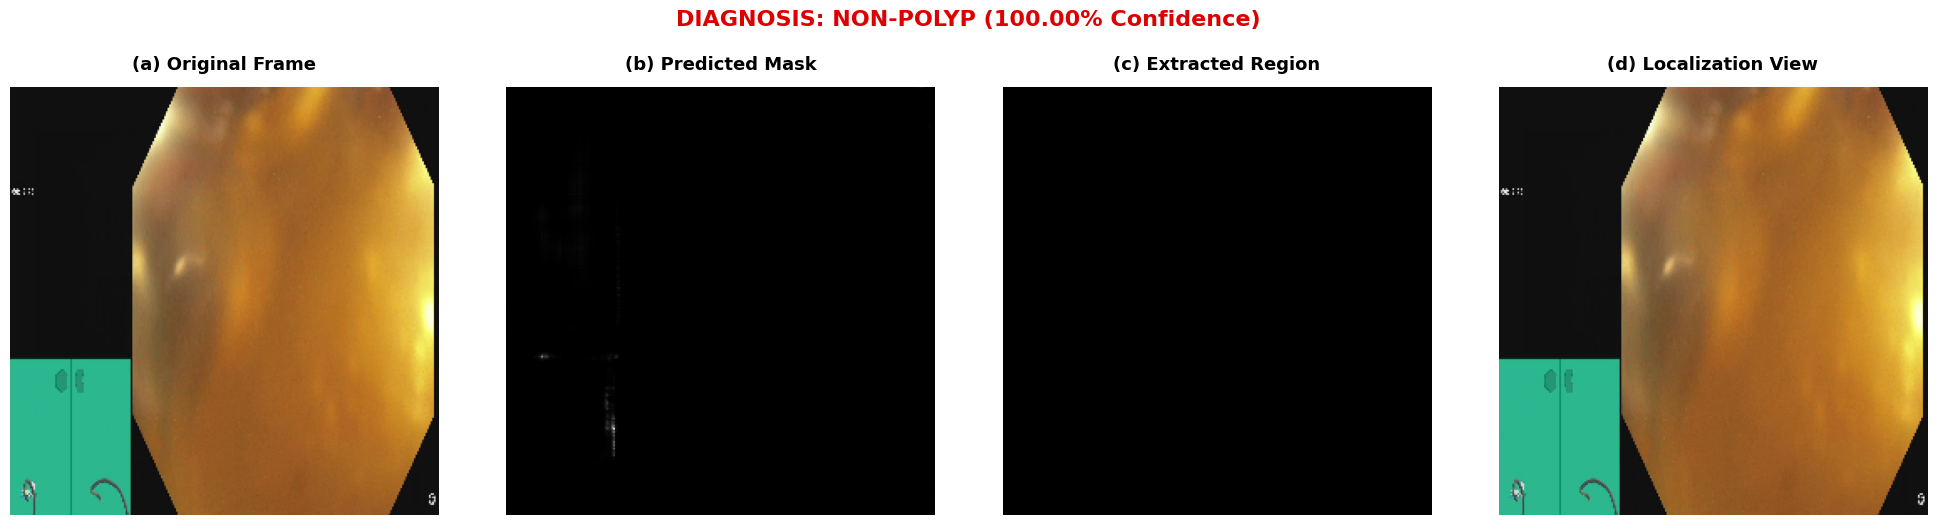


🎬 Processing Negative Dataset Specimen...
🏆 Qualitative evaluation plot successfully saved to: Neg3.png


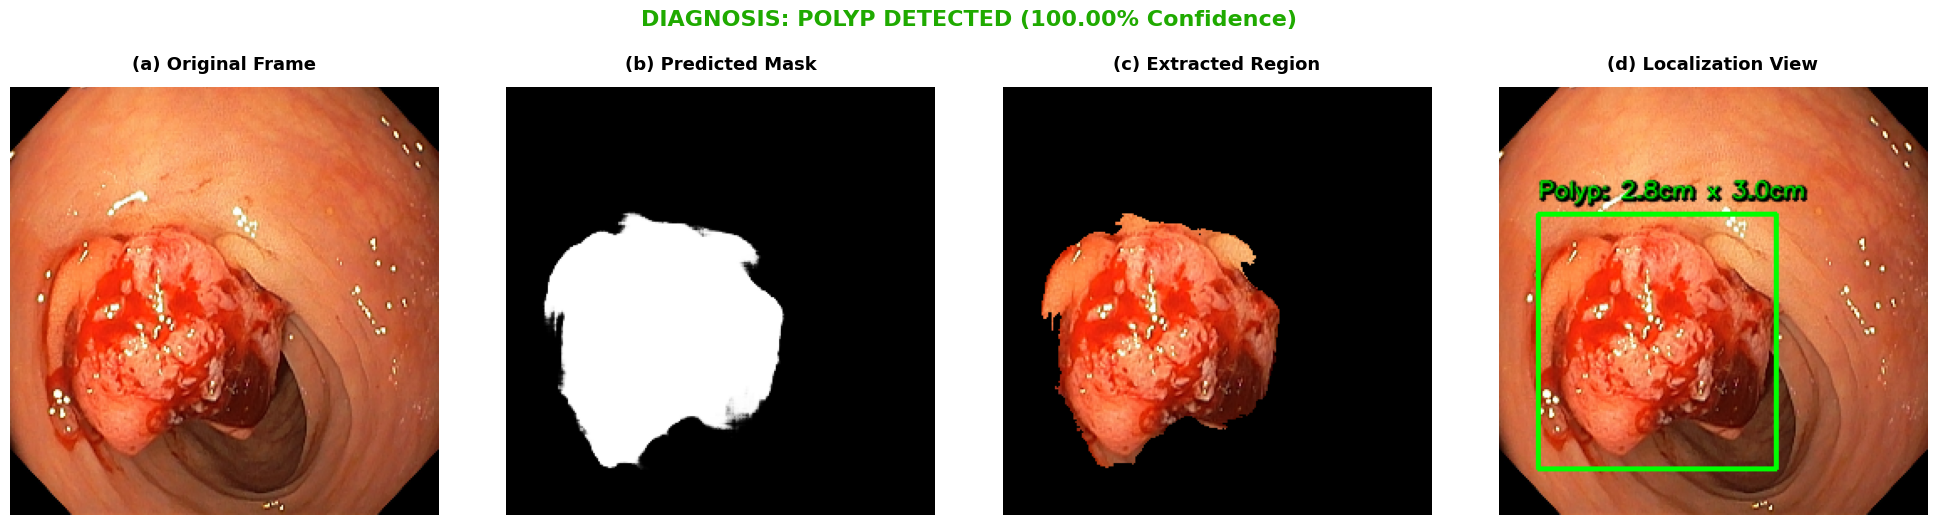


🎬 Processing Negative Dataset Specimen...
🏆 Qualitative evaluation plot successfully saved to: Neg4.png


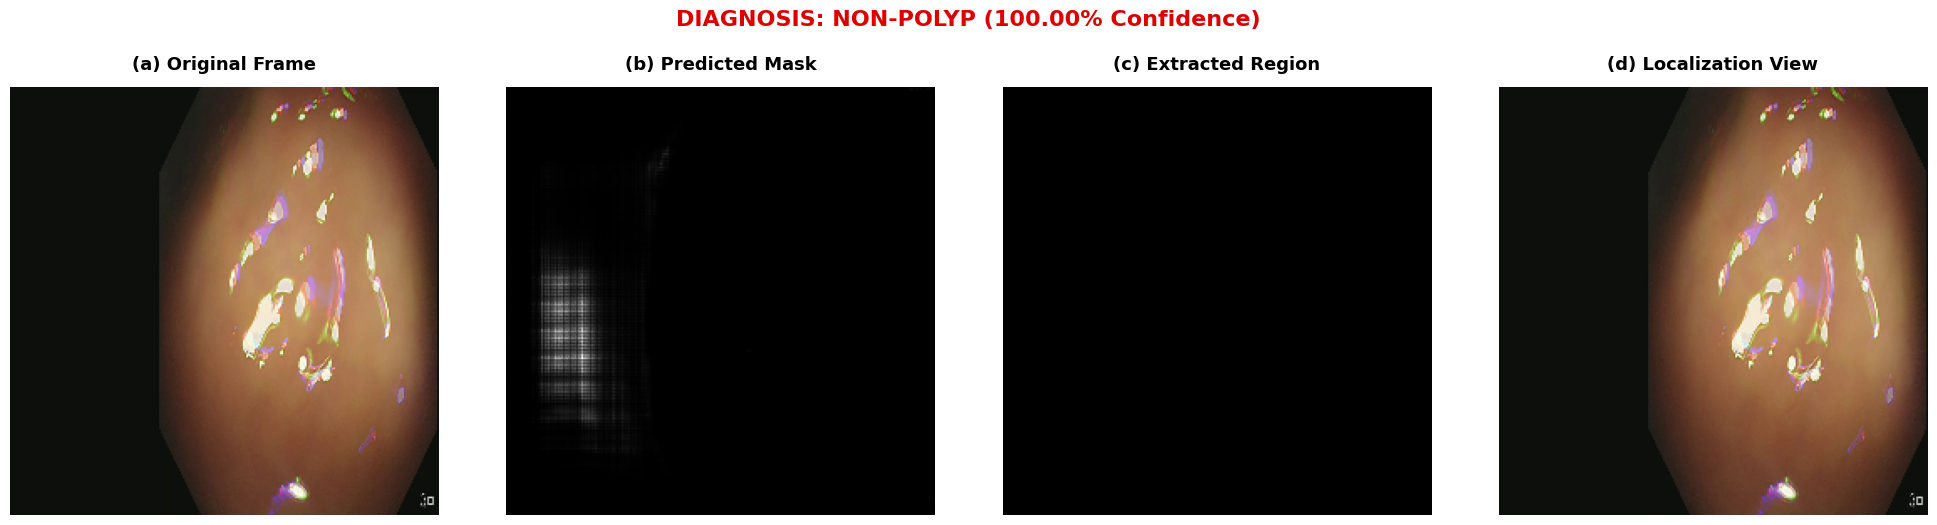


🎬 Processing Negative Dataset Specimen...
🏆 Qualitative evaluation plot successfully saved to: Neg5.png


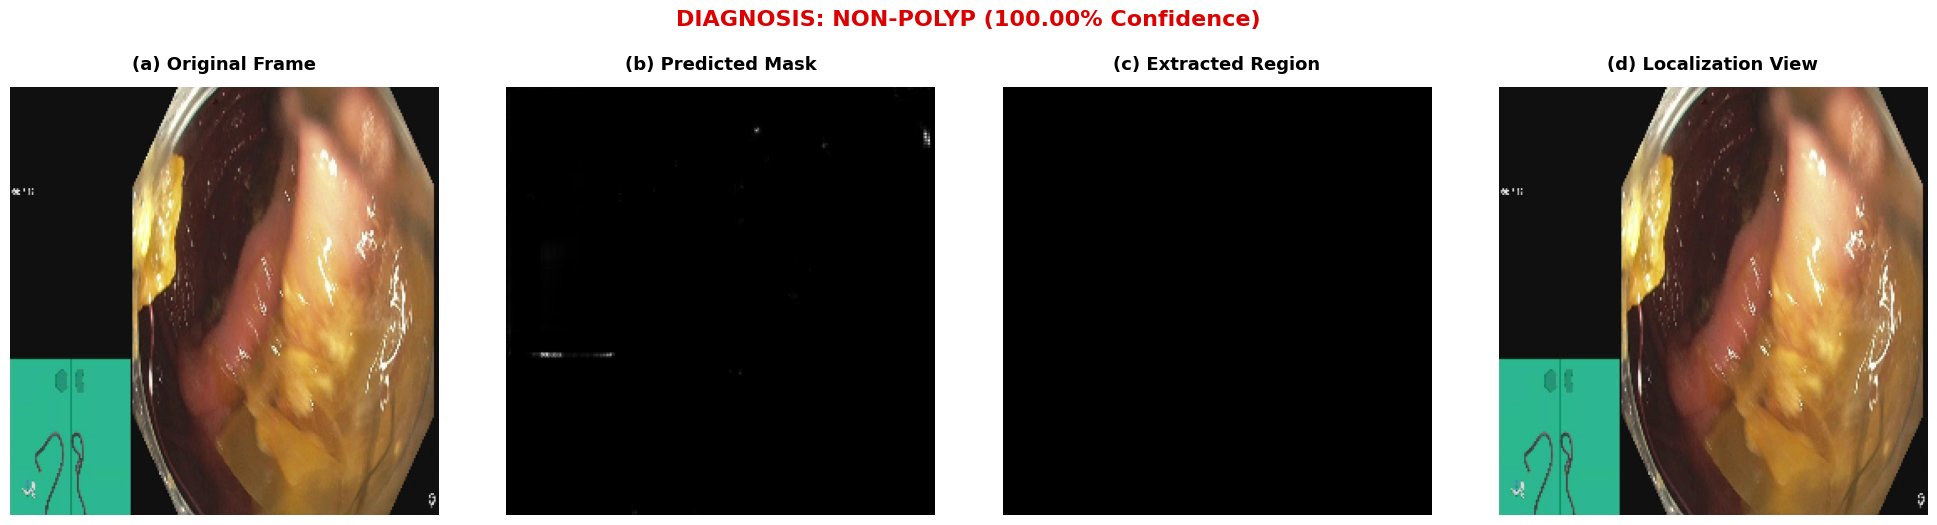

In [23]:
%matplotlib inline

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ GLOBAL INFERENCE CONFIGURATIONS
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

# Define your exact paths here
MODEL_PATH =  "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_28_5_02_ds_a_.keras"
TEST_POSITIVE_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/16_endocv2021_positive_557.jpg"
TEST_NEG_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq10_neg/EndoCV2021_seq10_neg_40_endocv2021_negative_754.jpg"
TEST_POSITIVE_IMAGE_PATH_2 = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/imagesAll_positive/176OLCV1_100H0890.jpg"
TEST_NEG2_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq13_neg/EndoCV2021_C5_seq3_246.jpg"
TEST_NEG3_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq3_neg/EndoCV2021_seq3_neg_2_endocv2021_positive_63.jpg"
# ─────────────────────────────────────────────────────────────────────────────
# 🎨 REFINED IMAGE LABELED LOCALIZATION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    """
    Draws a clean bounding box around the predicted polyp region with 
    high-contrast paper-grade typography and dimension mapping.
    """
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Calibration ratio: mapping image pixels to physical centimeters
    pixel_to_cm_ratio = 50 
    
    for cnt in contours:
        # Filter out minor noise elements or artifacts
        if cv2.contourArea(cnt) < 10:
            continue
            
        x, y, w, h = cv2.boundingRect(cnt)
        
        # Calculate real-world scale approximations
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"
        
        # 1. Draw High-Visibility Bounding Box (Green)
        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        
        # 2. Advanced Typography: Dynamic Text Positioning with Background Shadow
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        
        # Draw a clean black backdrop shadow for ultra-clear readability in papers
        cv2.putText(res_img, size_text, (x + 1, text_y + 1), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)
        # Draw the primary text layer
        cv2.putText(res_img, size_text, (x, text_y), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)
        
    return res_img

# ─────────────────────────────────────────────────────────────────────────────
# 🔮 MULTI-TASK INFERENCE CORE PIPELINE (SEGMENTATION + CLASSIFICATION)
# ─────────────────────────────────────────────────────────────────────────────
# 🔮 MULTI-TASK INFERENCE CORE PIPELINE (🎯 FIXED FOR 5-HEAD DEEP SUPERVISION)
def test_and_display(model, image_path, output_filename='result.png'):
    """
    Executes a joint multi-task prediction, extracting both pixel-level 
    segmentation masks and categorical classification diagnostic boundaries.
    """
    # 1. Read and pre-process target frame
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
        
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    inp = np.expand_dims(img_res / 255.0, axis=0).astype(np.float32)

    # 2. Target forward pass prediction (Extracting multi-head lists)
    pred_outputs = model.predict(inp, verbose=0)
    
    # 🎯 ফিক্স: আপনার ৫-হেড বিশিষ্ট মডেলের আউটপুট সঠিকভাবে হ্যান্ডেল করা
    if isinstance(pred_outputs, list) and len(pred_outputs) == 5:
        pred_mask_spatial = pred_outputs[0][0]  # Output Index 0: মেইন সেগমেন্টেশন মাস্ক [256, 256, 1]
        
        # ৫ নম্বর পজিশন (Index 4) হলো আসল ক্লাসিফিকেশন হেড ('clf_output')
        # কেরালা আউটপুট ফরম্যাট থেকে স্কেলার ভ্যালু বের করার জন্য .numpy() বা ফ্ল্যাট ইন্ডেক্সিং ব্যবহার
        clf_out_raw = pred_outputs[4][0]
        clf_prediction = float(clf_out_raw[0]) if hasattr(clf_out_raw, '__len__') else float(clf_out_raw)
        has_classification = True
        
    elif isinstance(pred_outputs, list) and len(pred_outputs) >= 2:
        # ওল্ড ২-হেড মডেল ব্যাকআপ (যদি কখনো আগের মডেল লোড করেন)
        pred_mask_spatial = pred_outputs[0][0]
        clf_out_raw = pred_outputs[1][0]
        clf_prediction = float(clf_out_raw[0]) if hasattr(clf_out_raw, '__len__') else float(clf_out_raw)
        has_classification = True
    else:
        # ফলব্যাক (শুধু সেগমেন্টেশন মোড)
        pred_mask_spatial = pred_outputs[0] if isinstance(pred_outputs, list) else pred_outputs[0]
        if len(pred_mask_spatial.shape) == 4:  # batch dimension হ্যান্ডেল করতে
            pred_mask_spatial = pred_mask_spatial[0]
        clf_prediction = 0.0
        has_classification = False

    # 3. Geometric extraction mappings
    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)

    # 4. Generate Dynamically Labeled Classification Title
    if has_classification:
        if clf_prediction >= 0.5:
            diagnostic_text = f"DIAGNOSIS: POLYP DETECTED ({clf_prediction * 100:.2f}% Confidence)"
            title_color = '#1faa00' # Vibrant Green
        else:
            diagnostic_text = f"DIAGNOSIS: NON-POLYP ({(1.0 - clf_prediction) * 100:.2f}% Confidence)"
            title_color = '#dd0000' # Deep Red
    else:
        diagnostic_text = "DIAGNOSIS: Segmentation Mode Active (No Classification Head Found)"
        title_color = 'orange'

    # 5. Generate Professional 4-Column Presentation Graph
    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    
    # High-level overview structural description super-title with live diagnosis
    plt.suptitle(diagnostic_text, fontsize=16, fontweight='bold', color=title_color, y=1.04)
    
    plt.tight_layout()
    
    # Save the polished output image to disk
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 Qualitative evaluation plot successfully saved to: {output_filename}")
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION STEP
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph into Memory (Shared Nodes)...")
    # Load model once outside the function to optimize execution loop
    shared_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print("✅ Multi-Task Graph successfully initialized.\n")
    
    print("🎬 Processing Positive Dataset Specimen...")
    test_and_display(shared_model, TEST_POSITIVE_IMAGE_PATH, 'thesis_positive_result.png')
    
    print("\n🎬 Processing Negative Dataset Specimen...")
    test_and_display(shared_model, TEST_NEG_IMAGE_PATH, 'thesis_negative_result.png')

    print("\n🎬 Processing Negative Dataset Specimen...")
    test_and_display(shared_model, TEST_POSITIVE_IMAGE_PATH_2,'Neg3.png')

    print("\n🎬 Processing Negative Dataset Specimen...")
    test_and_display(shared_model, TEST_NEG2_IMAGE_PATH,'Neg4.png')
    print("\n🎬 Processing Negative Dataset Specimen...")
    test_and_display(shared_model, TEST_NEG3_IMAGE_PATH,'Neg5.png')
